# 02 — Conference Popularity Analysis

Analisis konferensi dengan aktivitas publikasi tertinggi pada periode 2015–2025.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src import config
from src.viz import MUTED_FILL, SERIES, SURFACE, TEXT_MUTED, apply_style, save

apply_style()

## 1. Data

Analisis memakai dataset bersih. Peringkat hanya mencakup venue konferensi; venue workshop
pendamping (`*_workshops`) dikeluarkan. Trek pendamping seperti Findings, Extended Abstracts,
dan Demos dihitung sebagai bagian dari konferensi induknya.

In [2]:
papers = pd.read_parquet(config.CLEAN_PAPERS, columns=["paper_key", "year", "venue_id", "venue_name", "track"])
pairs = pd.read_parquet(config.CLEAN_PAPER_AUTHOR, columns=["paper_key", "author", "year", "venue_id"])
conferences = papers[~papers["venue_id"].str.endswith("_workshops")]
conference_pairs = pairs[~pairs["venue_id"].str.endswith("_workshops")]

pd.Series({
    "Makalah": len(papers),
    "Makalah pada venue konferensi": len(conferences),
    "Venue konferensi": conferences["venue_id"].nunique(),
    "Author unik": pairs["author"].nunique(),
    "Author unik pada venue konferensi": conference_pairs["author"].nunique(),
}).to_frame("jumlah")

,jumlah
Makalah,1996703
Makalah pada venue konferensi,1900336
Venue konferensi,4372
Author unik,1817265
Author unik pada venue konferensi,1773628


## 2. Top 10 Konferensi berdasarkan Jumlah Publikasi

In [3]:
by_papers = (conferences.pivot_table(index=["venue_id", "venue_name"], columns="track", aggfunc="size", fill_value=0)
             .reindex(columns=["main", "companion"], fill_value=0)
             .rename(columns={"main": "n_main", "companion": "n_companion"})
             .reset_index())
by_papers.columns.name = None
by_papers["n_papers"] = by_papers["n_main"] + by_papers["n_companion"]
by_papers["pct_papers"] = (100 * by_papers["n_papers"] / len(papers)).round(2)
by_papers = by_papers.sort_values(["n_papers", "venue_id"], ascending=[False, True]).reset_index(drop=True)
by_papers.insert(0, "rank", by_papers.index + 1)

top10_papers = by_papers.head(10)
top10_papers.to_csv(config.TABLES_DIR / "top10_conferences_by_papers.csv", index=False)
top10_papers

,rank,venue_id,venue_name,n_main,n_companion,n_papers,pct_papers
0,1,nips,NeurIPS,25178,97,25275,1.27
1,2,icassp,ICASSP,21125,0,21125,1.06
2,3,hci,HCI,19912,0,19912,1.00
3,4,igarss,IGARSS,19685,0,19685,0.99
4,5,aaai,AAAI,18443,0,18443,0.92
5,6,cvpr,CVPR,17429,0,17429,0.87
6,7,embc,EMBC,14677,0,14677,0.74
7,8,chi,CHI,8321,6327,14648,0.73
8,9,emnlp,EMNLP,8766,5686,14452,0.72
9,10,icml,ICML,13628,73,13701,0.69


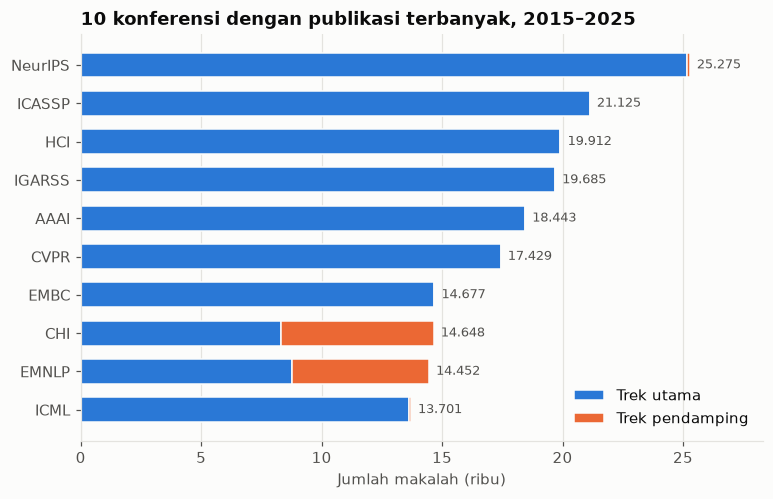

In [4]:
top = top10_papers.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top["venue_name"], top["n_main"] / 1e3, color=SERIES[0], height=0.65,
        edgecolor=SURFACE, linewidth=1, label="Trek utama")
ax.barh(top["venue_name"], top["n_companion"] / 1e3, left=top["n_main"] / 1e3, color=SERIES[1],
        height=0.65, edgecolor=SURFACE, linewidth=1, label="Trek pendamping")
for y, v in enumerate(top["n_papers"]):
    ax.text(v / 1e3 + 0.3, y, f"{v:,}".replace(",", "."), va="center", fontsize=8.5, color=TEXT_MUTED)
ax.set_xlim(0, top["n_papers"].max() / 1e3 * 1.12)
ax.set_xlabel("Jumlah makalah (ribu)")
ax.set_title("10 konferensi dengan publikasi terbanyak, 2015–2025")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "02_top10_by_papers")
plt.show()

Pengaruh penggabungan trek pendamping terhadap peringkat diperiksa dengan menyusun ulang
peringkat hanya dari trek utama.

In [5]:
main_only = (by_papers.sort_values(["n_main", "venue_id"], ascending=[False, True])
             .head(10)[["venue_id", "venue_name", "n_main"]].reset_index(drop=True))
main_only.insert(0, "rank_main", main_only.index + 1)
main_only["rank_all_tracks"] = main_only["venue_id"].map(by_papers.set_index("venue_id")["rank"])
main_only

,rank_main,venue_id,venue_name,n_main,rank_all_tracks
0,1,nips,NeurIPS,25178,1
1,2,icassp,ICASSP,21125,2
2,3,hci,HCI,19912,3
3,4,igarss,IGARSS,19685,4
4,5,aaai,AAAI,18443,5
5,6,cvpr,CVPR,17429,6
6,7,embc,EMBC,14677,7
7,8,icml,ICML,13628,10
8,9,iros,IROS,12832,12
9,10,icra,ICRA,12361,13


In [6]:
years = conferences[conferences["venue_id"].isin(top10_papers["venue_id"])]
years.pivot_table(index="venue_name", columns="year", aggfunc="size", fill_value=0).loc[top10_papers["venue_name"]]

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
venue_name,,,,,,,,,,,
NeurIPS,403,566,677,1009,1449,1918,2562,2834,3540,4494,5823
ICASSP,1198,1322,1321,1395,1735,1863,1723,1864,2720,2678,3306
HCI,1713,1470,1404,1365,1582,2153,1834,2025,2238,1801,2327
IGARSS,1353,1905,1569,2208,2273,1641,2152,1936,2059,2589,0
AAAI,673,691,783,1100,1340,1864,1960,1623,2034,2867,3508
CVPR,601,643,783,979,1294,1462,1660,2068,2353,2715,2871
EMBC,2004,1578,1124,1473,1669,1462,1639,1105,1237,1386,0
CHI,932,1125,1057,1203,1293,1318,1242,1128,1477,1705,2168
EMNLP,312,264,343,577,732,1235,1319,1487,2242,2450,3491


## 3. Top 10 Konferensi berdasarkan Jumlah Author Unik

Author unik dihitung per konferensi sepanjang 2015–2025: author yang menulis beberapa makalah
pada konferensi yang sama dihitung satu kali. Identitas author mengikuti nama DBLP beserta
nomor homonimnya.

In [7]:
by_authors = (conference_pairs.groupby("venue_id")["author"].nunique().rename("n_authors").reset_index()
              .merge(by_papers[["venue_id", "venue_name", "n_papers", "rank"]].rename(columns={"rank": "rank_papers"}),
                     on="venue_id"))
by_authors["pct_authors"] = (100 * by_authors["n_authors"] / pairs["author"].nunique()).round(2)
by_authors = by_authors.sort_values(["n_authors", "venue_id"], ascending=[False, True]).reset_index(drop=True)
by_authors.insert(0, "rank", by_authors.index + 1)
by_authors = by_authors[["rank", "venue_id", "venue_name", "n_authors", "pct_authors", "n_papers", "rank_papers"]]

top10_authors = by_authors.head(10)
top10_authors.to_csv(config.TABLES_DIR / "top10_conferences_by_authors.csv", index=False)
top10_authors

,rank,venue_id,venue_name,n_authors,pct_authors,n_papers,rank_papers
0,1,nips,NeurIPS,57358,3.16,25275,1
1,2,aaai,AAAI,44683,2.46,18443,5
2,3,icassp,ICASSP,41063,2.26,21125,2
3,4,embc,EMBC,39311,2.16,14677,7
4,5,hci,HCI,37845,2.08,19912,3
5,6,igarss,IGARSS,35207,1.94,19685,4
6,7,cvpr,CVPR,34940,1.92,17429,6
7,8,emnlp,EMNLP,33355,1.84,14452,9
8,9,icml,ICML,31659,1.74,13701,10
9,10,iros,IROS,31178,1.72,12832,12


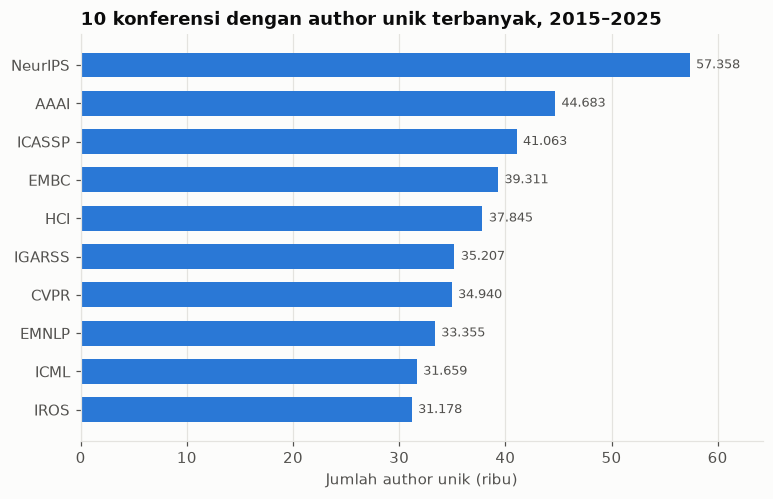

In [8]:
top = top10_authors.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top["venue_name"], top["n_authors"] / 1e3, color=SERIES[0], height=0.65)
for y, v in enumerate(top["n_authors"]):
    ax.text(v / 1e3 + 0.6, y, f"{v:,}".replace(",", "."), va="center", fontsize=8.5, color=TEXT_MUTED)
ax.set_xlim(0, top["n_authors"].max() / 1e3 * 1.12)
ax.set_xlabel("Jumlah author unik (ribu)")
ax.set_title("10 konferensi dengan author unik terbanyak, 2015–2025")
ax.grid(axis="y", visible=False)
save(fig, "02_top10_by_authors")
plt.show()

Pengaruh trek pendamping diperiksa dengan menghitung ulang author unik dari makalah trek utama saja.

In [9]:
main_keys = conferences.loc[conferences["track"] == "main", "paper_key"]
main_authors = (conference_pairs[conference_pairs["paper_key"].isin(main_keys)]
                .groupby("venue_id")["author"].nunique().rename("n_authors_main").reset_index()
                .sort_values(["n_authors_main", "venue_id"], ascending=[False, True]).head(10).reset_index(drop=True))
main_authors.insert(0, "rank_main", main_authors.index + 1)
main_authors["rank_all_tracks"] = main_authors["venue_id"].map(by_authors.set_index("venue_id")["rank"])
main_authors

,rank_main,venue_id,n_authors_main,rank_all_tracks
0,1,nips,56670,1
1,2,aaai,44683,2
2,3,icassp,41063,3
3,4,embc,39311,4
4,5,hci,37845,5
5,6,igarss,35207,6
6,7,cvpr,34940,7
7,8,icml,31439,9
8,9,iros,31178,10
9,10,ijcnn,29766,12


## 4. Tren Publikasi 2015–2025

### 4.1 Total Publikasi per Tahun

Tren dihitung pada venue konferensi, sama dengan cakupan peringkat. Indeks menyatakan nilai
setiap tahun relatif terhadap 2015 (2015 = 100).

In [10]:
top10_ids = top10_papers["venue_id"]
yearly = pd.DataFrame({
    "n_papers": conferences.groupby("year").size(),
    "n_authors": conference_pairs.groupby("year")["author"].nunique(),
    "n_venues": conferences.groupby("year")["venue_id"].nunique(),
})
yearly["pct_change"] = (100 * yearly["n_papers"].pct_change()).round(1)
yearly["index_papers"] = (100 * yearly["n_papers"] / yearly["n_papers"].iloc[0]).round(1)
yearly["index_authors"] = (100 * yearly["n_authors"] / yearly["n_authors"].iloc[0]).round(1)
yearly["pct_top10"] = (100 * conferences[conferences["venue_id"].isin(top10_ids)].groupby("year").size()
                       / yearly["n_papers"]).round(2)
yearly.to_csv(config.TABLES_DIR / "publication_trend.csv")
yearly

,n_papers,n_authors,n_venues,pct_change,index_papers,index_authors,pct_top10
year,,,,,,,
2015,152670,287590,1954,NaN,100.0,100.0,6.20
2016,153250,293551,1995,0.4,100.4,102.1,6.45
2017,159190,313021,2041,3.9,104.3,108.8,5.96
2018,166888,335689,2128,4.8,109.3,116.7,7.15
2019,178903,365517,2209,7.2,117.2,127.1,7.90
2020,163163,343168,2010,-8.8,106.9,119.3,9.81
2021,170538,364557,2173,4.5,111.7,126.8,10.13
2022,169667,372479,2227,-0.5,111.1,129.5,10.20
2023,192181,420468,2309,13.3,125.9,146.2,11.31


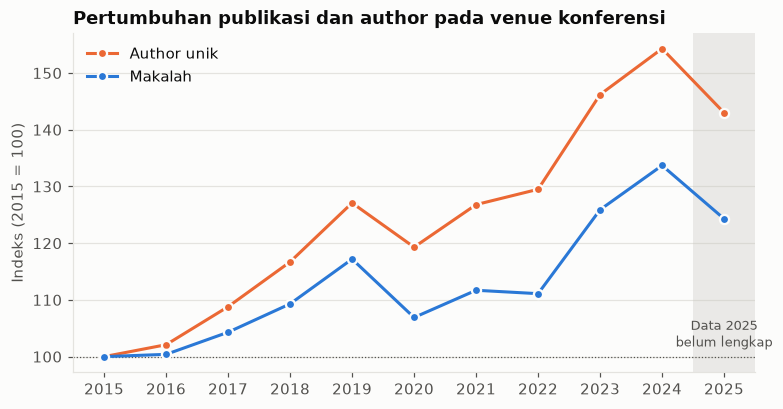

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(2024.5, 2025.5, color=MUTED_FILL, alpha=0.35, linewidth=0)
ax.text(2025, 101, "Data 2025\nbelum lengkap", ha="center", va="bottom", fontsize=8.5, color=TEXT_MUTED)
ax.axhline(100, color=TEXT_MUTED, linewidth=0.8, linestyle=":")
for column, label, color in [("index_authors", "Author unik", SERIES[1]), ("index_papers", "Makalah", SERIES[0])]:
    ax.plot(yearly.index, yearly[column], color=color, linewidth=2, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
ax.set_xticks(yearly.index)
ax.set_xlim(2014.5, 2025.5)
ax.set_ylabel("Indeks (2015 = 100)")
ax.set_title("Pertumbuhan publikasi dan author pada venue konferensi")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
save(fig, "02_publication_trend")
plt.show()

### 4.2 Tren 10 Konferensi Teratas

Konferensi yang ditampilkan adalah 10 besar berdasarkan jumlah publikasi. Laju pertumbuhan
tahunan (CAGR) dihitung untuk 2015–2024, karena data 2025 belum lengkap. Tahun tanpa makalah
tidak digambar, dan segmen 2024–2025 digambar putus-putus.

In [12]:
years = list(range(2015, 2026))
trend = (conferences[conferences["venue_id"].isin(top10_ids)]
         .pivot_table(index="venue_id", columns="year", aggfunc="size", fill_value=0)
         .reindex(top10_ids))
trend.columns.name = None
trend.insert(0, "venue_name", top10_papers.set_index("venue_id")["venue_name"])
trend["growth_2015_2024"] = (trend[2024] / trend[2015]).round(2)
trend["cagr_2015_2024"] = (100 * ((trend[2024] / trend[2015]) ** (1 / 9) - 1)).round(1)
trend.to_csv(config.TABLES_DIR / "top10_conferences_trend.csv")
trend

,venue_name,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,growth_2015_2024,cagr_2015_2024
venue_id,,,,,,,,,,,,,,
nips,NeurIPS,403,566,677,1009,1449,1918,2562,2834,3540,4494,5823,11.15,30.7
icassp,ICASSP,1198,1322,1321,1395,1735,1863,1723,1864,2720,2678,3306,2.24,9.3
hci,HCI,1713,1470,1404,1365,1582,2153,1834,2025,2238,1801,2327,1.05,0.6
igarss,IGARSS,1353,1905,1569,2208,2273,1641,2152,1936,2059,2589,0,1.91,7.5
aaai,AAAI,673,691,783,1100,1340,1864,1960,1623,2034,2867,3508,4.26,17.5
cvpr,CVPR,601,643,783,979,1294,1462,1660,2068,2353,2715,2871,4.52,18.2
embc,EMBC,2004,1578,1124,1473,1669,1462,1639,1105,1237,1386,0,0.69,-4.0
chi,CHI,932,1125,1057,1203,1293,1318,1242,1128,1477,1705,2168,1.83,6.9
emnlp,EMNLP,312,264,343,577,732,1235,1319,1487,2242,2450,3491,7.85,25.7


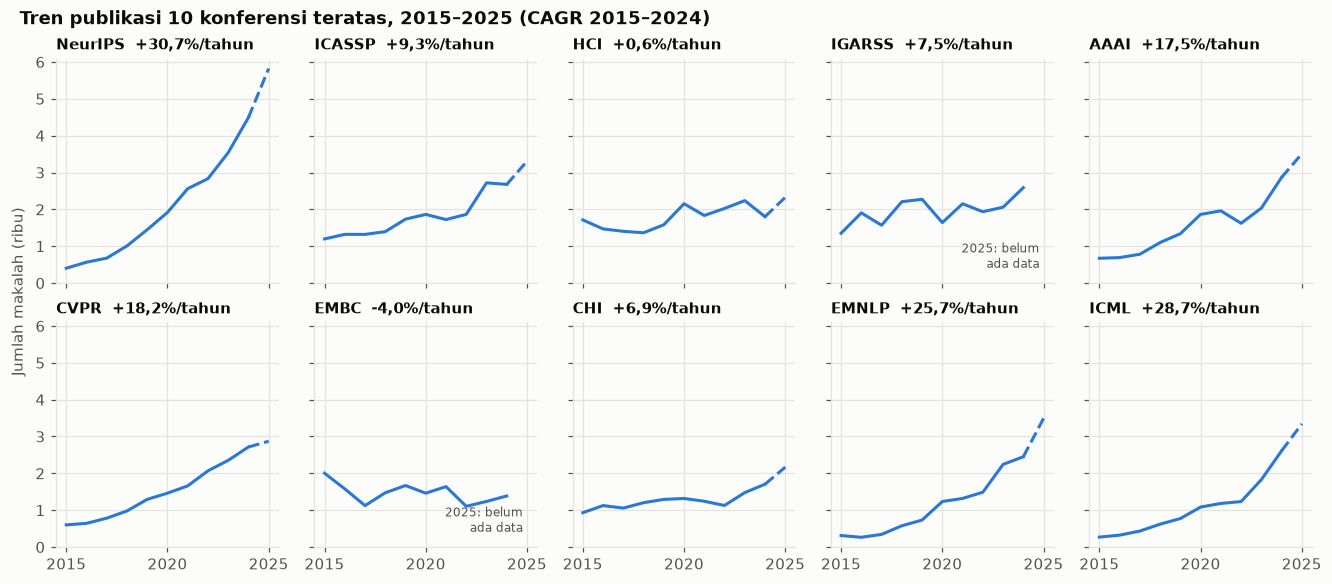

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2), sharex=True, sharey=True, layout="constrained")
for ax, (_, row) in zip(axes.flat, trend.iterrows()):
    counts = row[years].astype(float)
    counts = counts.mask(counts == 0) / 1e3
    ax.plot(years[:-1], counts[years[:-1]], color=SERIES[0], linewidth=2)
    ax.plot(years[-2:], counts[years[-2:]], color=SERIES[0], linewidth=2, linestyle="--")
    if pd.isna(counts[2025]):
        ax.text(2024.8, 0.3, "2025: belum\nada data", ha="right", va="bottom", fontsize=8, color=TEXT_MUTED)
    cagr = f"{row['cagr_2015_2024']:+.1f}".replace(".", ",")
    ax.set_title(f"{row['venue_name']}  {cagr}%/tahun", fontsize=10)
    ax.set_xticks([2015, 2020, 2025])
    ax.set_ylim(bottom=0)
fig.get_layout_engine().set(wspace=0.06)
fig.supylabel("Jumlah makalah (ribu)", color=TEXT_MUTED, fontsize=10)
fig.suptitle("Tren publikasi 10 konferensi teratas, 2015–2025 (CAGR 2015–2024)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
save(fig, "02_top10_trend")
plt.show()

### 4.3 Kelengkapan Data 2025

Kelengkapan data 2025 diperiksa pada venue yang rutin aktif, yaitu venue yang memiliki makalah
pada 2023 dan 2024.

In [14]:
venue_year = conferences.groupby(["venue_id", "year"]).size().unstack(fill_value=0)
regular = venue_year[(venue_year[2023] > 0) & (venue_year[2024] > 0)]
missing = regular[regular[2025] == 0]

pd.Series({
    "Venue dengan makalah pada 2023 dan 2024": len(regular),
    "Venue tersebut yang belum memiliki makalah 2025": len(missing),
    "Makalah 2024 pada venue tersebut": int(missing[2024].sum()),
}).to_frame("jumlah")

,jumlah
Venue dengan makalah pada 2023 dan 2024,1721
Venue tersebut yang belum memiliki makalah 2025,447
Makalah 2024 pada venue tersebut,32146


In [15]:
(missing[[2023, 2024]].join(by_papers.set_index("venue_id")["venue_name"])
 .sort_values(2024, ascending=False).head(10))

,2023,2024,venue_name
venue_id,,,
igarss,2059,2589,IGARSS
icccnt,1489,2119,ICCCNT
embc,1237,1386,EMBC
ieeesensors,473,558,IEEE SENSORS
gcce,426,494,GCCE
atal,528,460,AAMAS
isgteurope,318,422,ISGT Europe
eacl,510,405,EACL
icce-tw,423,384,ICCE-TW
